--- Génération des 5 visualisations ---


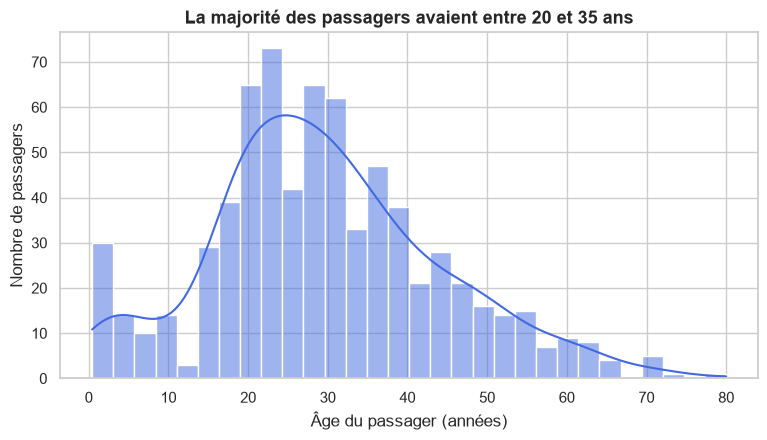

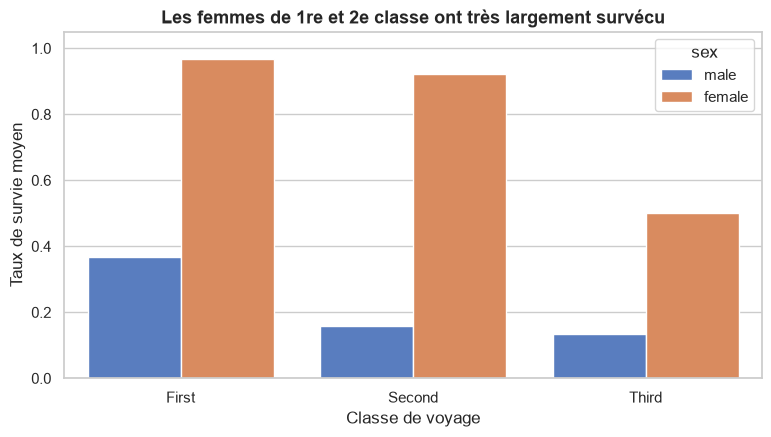

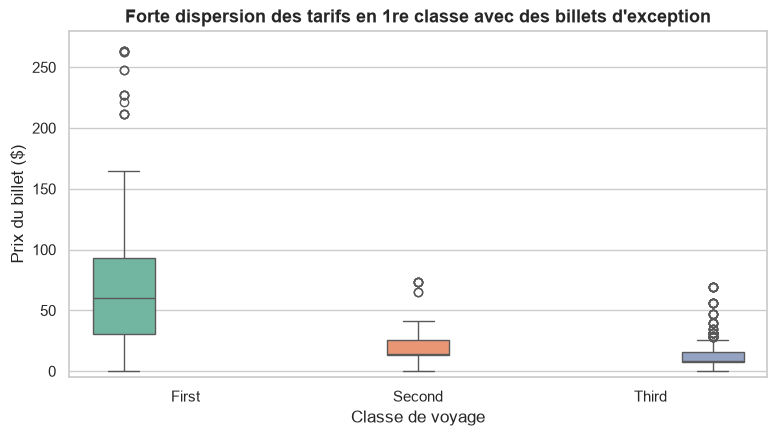

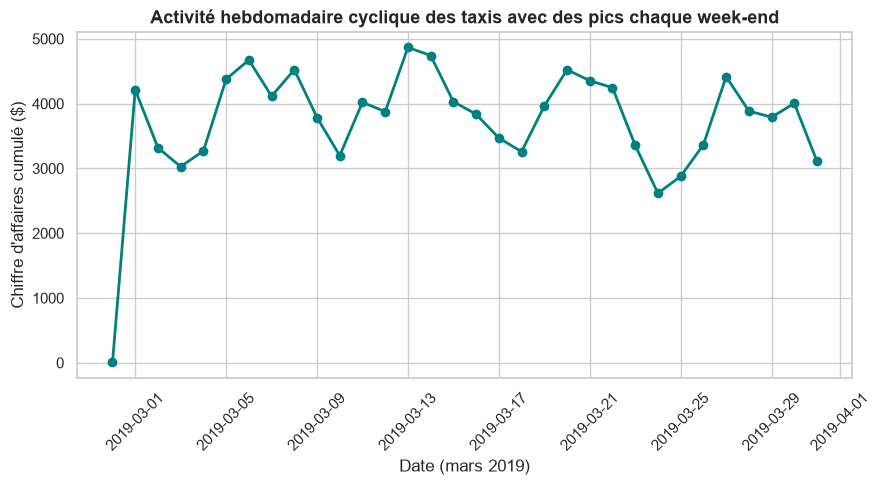

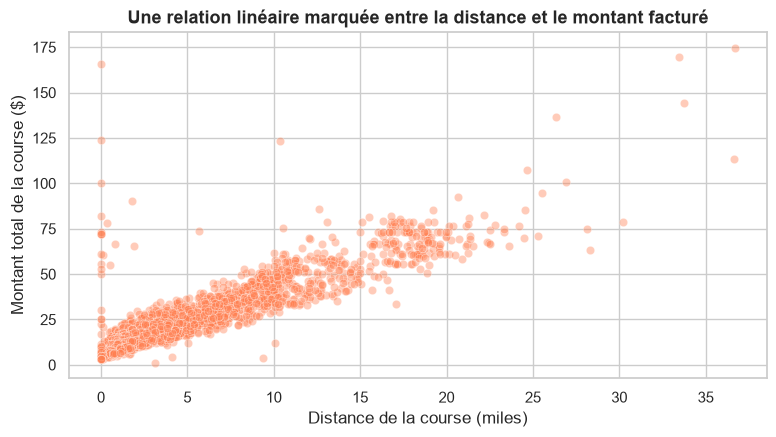

Les 5 figures ont été générées et enregistrées avec succès dans le dossier figures/ !


In [1]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Création sécurisée des dossiers de sortie
os.makedirs("figures", exist_ok=True)
os.makedirs("../figures", exist_ok=True)

# Configuration esthétique Seaborn
sns.set_theme(style="whitegrid", font_scale=1.0)

# Chargement des jeux de données
titanic = sns.load_dataset("titanic")
taxis = sns.load_dataset("taxis")
taxis["pickup"] = pd.to_datetime(taxis["pickup"])

print("--- Génération des 5 visualisations ---")

# 1. Quel âge avaient les passagers ? (Histogramme)
fig1, ax1 = plt.subplots(figsize=(9, 4.5))
sns.histplot(data=titanic, x="age", bins=30, kde=True, color="royalblue", ax=ax1)
ax1.set_title("La majorité des passagers avaient entre 20 et 35 ans", fontsize=13, fontweight="bold")
ax1.set_xlabel("Âge du passager (années)")
ax1.set_ylabel("Nombre de passagers")
fig1.savefig("figures/01_distribution_ages.png", dpi=150, bbox_inches="tight")
fig1.savefig("../figures/01_distribution_ages.png", dpi=150, bbox_inches="tight")
plt.show()

# 2. La survie selon la classe et le sexe (Diagramme en barres)
fig2, ax2 = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=titanic, x="class", y="survived", hue="sex", palette="muted", errorbar=None, ax=ax2)
ax2.set_title("Les femmes de 1re et 2e classe ont très largement survécu", fontsize=13, fontweight="bold")
ax2.set_xlabel("Classe de voyage")
ax2.set_ylabel("Taux de survie moyen")
ax2.set_ylim(0, 1.05)
fig2.savefig("figures/02_survie_classe_sexe.png", dpi=150, bbox_inches="tight")
fig2.savefig("../figures/02_survie_classe_sexe.png", dpi=150, bbox_inches="tight")
plt.show()

# 3. Le prix du billet selon la classe (Boîte à moustaches)
fig3, ax3 = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=titanic, x="class", y="fare", hue="class", palette="Set2", legend=False, ax=ax3)
ax3.set_title("Forte dispersion des tarifs en 1re classe avec des billets d'exception", fontsize=13, fontweight="bold")
ax3.set_xlabel("Classe de voyage")
ax3.set_ylabel("Prix du billet ($)")
ax3.set_ylim(-5, 280)
fig3.savefig("figures/03_prix_billet_classe.png", dpi=150, bbox_inches="tight")
fig3.savefig("../figures/03_prix_billet_classe.png", dpi=150, bbox_inches="tight")
plt.show()

# 4. Taxis : Le chiffre d'affaires jour après jour (Courbe temporelle)
ca_jour = taxis.set_index("pickup").resample("D")["total"].sum()
fig4, ax4 = plt.subplots(figsize=(10, 4.5))
ax4.plot(ca_jour.index, ca_jour.values, marker="o", color="teal", linewidth=2)
ax4.set_title("Activité hebdomadaire cyclique des taxis avec des pics chaque week-end", fontsize=13, fontweight="bold")
ax4.set_xlabel("Date (mars 2019)")
ax4.set_ylabel("Chiffre d'affaires cumulé ($)")
plt.xticks(rotation=45)
fig4.savefig("figures/04_taxis_ca_journalier.png", dpi=150, bbox_inches="tight")
fig4.savefig("../figures/04_taxis_ca_journalier.png", dpi=150, bbox_inches="tight")
plt.show()

# 5. Taxis : Le lien entre distance et prix (Nuage de points)
fig5, ax5 = plt.subplots(figsize=(9, 4.5))
sns.scatterplot(data=taxis, x="distance", y="total", alpha=0.4, color="coral", ax=ax5)
ax5.set_title("Une relation linéaire marquée entre la distance et le montant facturé", fontsize=13, fontweight="bold")
ax5.set_xlabel("Distance de la course (miles)")
ax5.set_ylabel("Montant total de la course ($)")
fig5.savefig("figures/05_taxis_distance_prix.png", dpi=150, bbox_inches="tight")
fig5.savefig("../figures/05_taxis_distance_prix.png", dpi=150, bbox_inches="tight")
plt.show()

print("Les 5 figures ont été générées et enregistrées avec succès dans le dossier figures/ !")


### Justifications et conclusions des 5 visualisations

| Question & Graphique | Justification du type de graphique | Conclusion métier |
| :--- | :--- | :--- |
| **1. Âge des passagers**<br>*(Histogramme)* | Idéal pour observer la forme de la distribution d'une **variable quantitative continue unique** (`age`). | La majorité des passagers étaient de jeunes adultes (20 à 35 ans), avec un second petit pic chez les jeunes enfants (0-5 ans). |
| **2. Survie par classe et sexe**<br>*(Barres groupées)* | Parfait pour comparer une **proportion** (`survived`) selon deux variables catégorielles (`class` et `sex`). | Le taux de survie dépasse 90 % pour les femmes de 1re et 2e classe, alors qu'il s'effondre à 13.5 % pour les hommes de 3e classe. |
| **3. Prix selon la classe**<br>*(Boîte à moustaches)* | Visualise la médiane, les quartiles et les valeurs extrêmes d'une **mesure continue par catégorie**. | Les billets de 2e et 3e classe restent très resserrés sous 30 $, tandis que la 1re classe montre une forte dispersion et des valeurs au-delà de 250 $. |
| **4. CA des taxis par jour**<br>*(Courbe temporelle)* | Adapté pour restituer une **évolution chronologique continue** jour après jour. | L'activité présente une périodicité hebdomadaire nette : les recettes culminent les vendredis/samedis (> 4 000 $) et baissent en début de semaine. |
| **5. Distance vs Prix**<br>*(Nuage de points)* | Standard pour étudier la **corrélation et le comportement conjoint entre deux mesures continues**. | Forte dépendance linéaire : le prix croît proportionnellement à la distance, avec un forfait de prise en charge initial et quelques forfaits aéroports fixes. |
